#TiiQU Non Academic Trustworthiness Score

- Developer : Kinsuk Ghatak
- Final updates : Feb 2026

**Overview :** This Jupyter notebook implements an automated trustworthiness scoring system for various entities (startups, media organizations, NGOs, etc.) by analyzing their online presence, certifications, transparency reports, and published documents. The system extracts and scores information across multiple dimensions to provide a comprehensive non-academic trustworthiness assessment.



**Purpose:**
The purpose of this code is to extract and scrape information from official entity websites to evaluate their trustworthiness across various dimensions including affiliations, awards, data security, sustainability practices, scientific validity, content integrity, and transparency metrics.

**TiiQU Non Academic Trustworthiness Score :**
The Purpose of this code is to extract and scrape information of an non academic entities like startups, NGOs, Media etc. from multiple sources to determine the transparency and trustworthyness score:
the code base will:
- Explore the websites of each targeted entity, discover elements that accomunate them in term of trustworthiness against various metrics like Awards, recognitions, Data security, sustainability, content integrity and so on.
- Scrape the relevant information either from the found website or from pdf reports.
- Finally, depending on the keywords match or found website an automated system that will assign an id Tq score to the entity

The dimensins and subdimensions for the score are as below with details on the scores used for different types of entities:

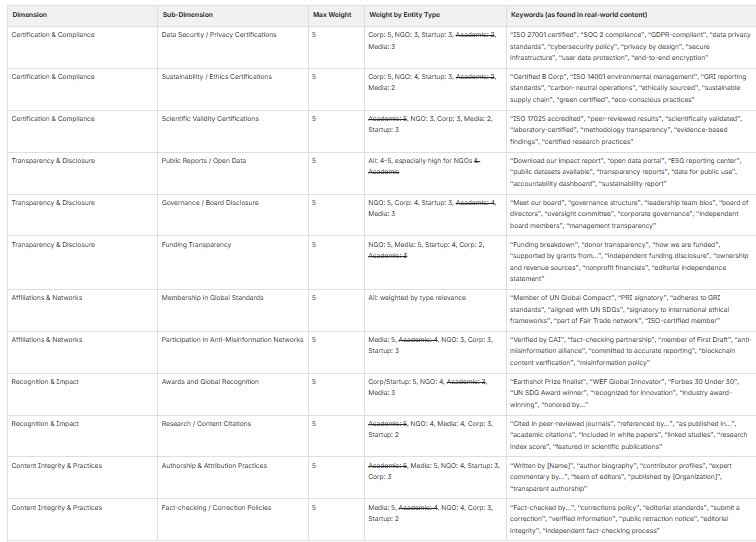




Refer to the link for more details on the process:
https://webcrawler.atlassian.net/wiki/spaces/WD/pages/77168699/Examples+of+targeted+non-academic+partners


- Code base Developed by Kinsuk Ghatak
- kinsuk.g@tiiqunetwork.onmicrosoft.com
- Last updated on: 05-02-2026
- General processflow :

```
┌─────────────────────────────────────────────────────────────────┐
│                    INPUT: Entity Name + Type                     │
└─────────────────────────────────────────────────────────────────┘
                              ↓
┌─────────────────────────────────────────────────────────────────┐
│              STEP 1: Web Search (Serper API)                │
│  • Find official website                                        │
│  • Find category-specific pages                                 │
│  • Find PDF documents                                           │
└─────────────────────────────────────────────────────────────────┘
                              ↓
┌─────────────────────────────────────────────────────────────────┐
│              STEP 2: Content Extraction                          │
│  • Scrape webpage text (BeautifulSoup)                          │
│  • Extract PDF text (pdfplumber/PyPDF2)                         │
│  • Find PDF links on pages                                      │
└─────────────────────────────────────────────────────────────────┘
                              ↓
┌─────────────────────────────────────────────────────────────────┐
│              STEP 3: Keyword Analysis                            │
│  • Search for category-specific keywords                        │
│  • Count keyword occurrences                                    │
│  • Identify found keywords                                      │
└─────────────────────────────────────────────────────────────────┘
                              ↓
┌─────────────────────────────────────────────────────────────────┐
│              STEP 4: Scoring                                     │
│  • PDF found but no keywords → Score = 1                        │
│  • Keywords found → Score = base_score (entity-specific)        │
│  • Nothing found → Score = 0                                    │
└─────────────────────────────────────────────────────────────────┘
                              ↓
┌─────────────────────────────────────────────────────────────────┐
│              OUTPUT: Trustworthiness Score DataFrame             │
│  • 12 categories analyzed                                       │
│  • Keywords found per category                                  │
│  • Individual scores per category                               │
│  • Total trustworthiness score                                  │
└─────────────────────────────────────────────────────────────────┘
```

The general process flow is as below

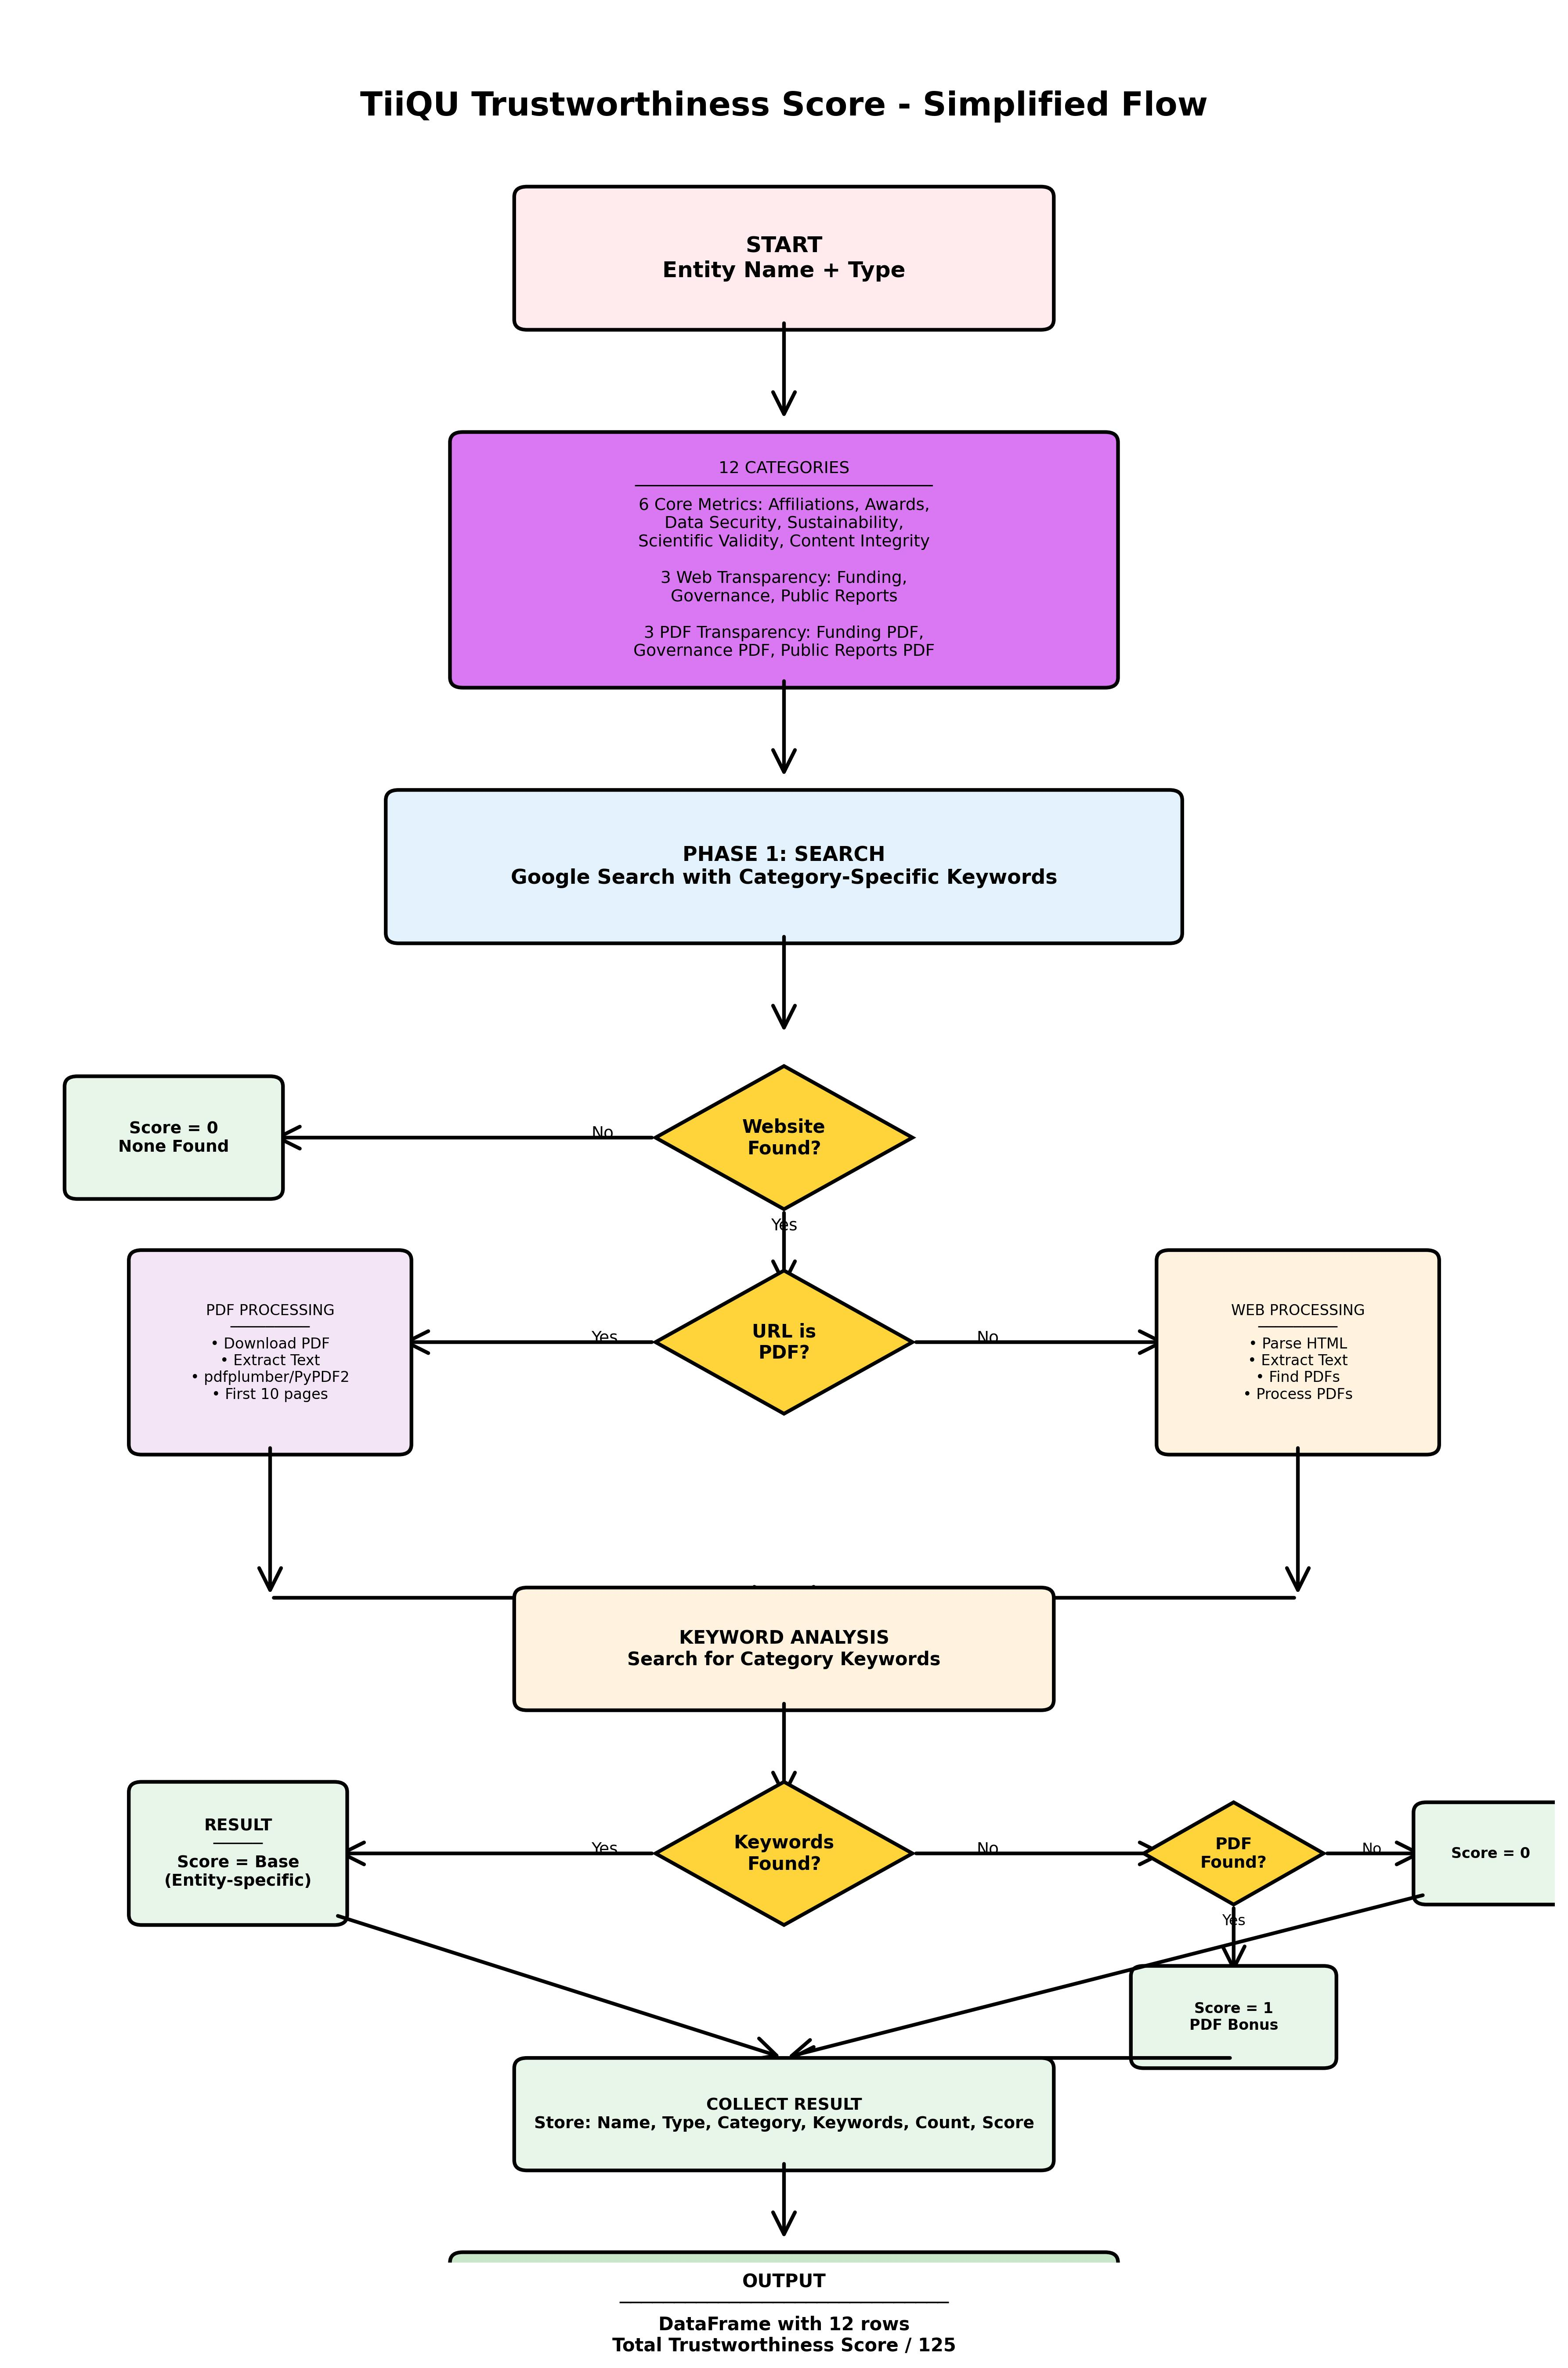

# Sec 1 : Install packages and import libraries

In [ ]:
## Install the required packages:

! pip install pdfplumber PyPDF2
! pip install fake_useragent

! pip install requests beautifulsoup4 googlesearch-python fake-useragent PyMuPDF
! pip install PyMuPDF
! pip install selenium
! pip install scrapy
! pip install rapidfuzz



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 770.6 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.7/161.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.1/24.1 MB 71.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.0/512.0 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.6/131.6 kB 9.9 MB/s eta 0:00:00
  Attempting uninstall: urllib3
    Found existing i

In [ ]:
# Import relevant libraries:

import scrapy
from bs4 import BeautifulSoup
import re
import json
import io

import requests
from bs4 import BeautifulSoup
import json
import time
from datetime import datetime

from fake_useragent import UserAgent

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
import time
import pandas as pd
from io import StringIO

import re
from googlesearch import search

import pandas as pd
from datetime import datetime
import calendar

from urllib.parse import  urljoin, urlparse, unquote,parse_qs, quote_plus, quote


from tkinter import simpledialog, Tk


import fitz  # PyMuPDF

import PyPDF2
import pdfplumber

from pathlib import Path


# Sec 2 : Define keywords and scores for  Affiliations , Awards, Regonitions, Sustaibility and Certifications together :

In [ ]:
# List of certifications and affiliations to check for
Affiliations = [
    "UN Global Compact","Principles for Responsible Investment", "PRI", "Climate Action 100+",
    "Global Reporting Initiative", "GRI", "GRI standards", "Fair Trade network", "ISO-certified member",
    "Science Based Targets initiative","UNPRI", "CAI", "OECD", "ICLEI", "RE100", "CDP", "WBCSD",
     "IIRC", "ISO member", "sustainability coalition", "blockchain verification","Verified by CAI",
    "First Draft","anti-misinformation alliance","blockchain content verification","fact-checking partnership",
    "misinformation policy","member of First Draft","fact-checking partnership"

]


# List of awards and recognition to check for
awards_recog = [
    "Earthshot", "Earthshot Prize finalist", "WEF Pioneer",
    "Earthshot Prize", "WEF Global" ,"WEF Global Innovator","Innovator", "UN SDG award",
    "Ashoka Fellow", "Bloomberg NEF Pioneer", "World Changing Ideas", "Forbes 30 Under 30",
    "Global Good Award", "Fast Company recognition", "industry award-winning","honored by"
    "UN award, environmental award", "UN SDG Award winner",
    "social impact award", "green tech recognition","Cited in peer-reviewed journals",
    "referenced by","as published in","academic citations","included in white papers",
    "linked studies","research index score","featured in scientific publications"
]


# List of data security certifications to check for
data_security_keys = ["ISO 27001","ISO 27001 certified", "ISO 27701", "SOC 2", "SOC 2 compliance",
                      "SOC 1", "GDPR", "GDPR-compliant","CCPA", "HIPAA",
                      "Data privacy standards","cybersecurity policy","privacy by design",
                      "secure infrastructure", "user data protection", "end to end encryption",
                      "privacy policy certification","data privacy standards","cybersecurity policy",
                     "privacy by design","user data protection","end-to-end encryption","secure infrastructure"]



# List of sustainability certifications to check for
sustainability_keys = ["GRI","GRI reporting standards" ,"ISO 14001", "ISO 26000", "B Corp", "Certified B Corp",
                       "LEED certified", "EcoVadis", "SA8000","ISO 14001 environmental management",
                      "Carbon Trust","carbon-neutral operations", "RBA certification", "CDP disclosure",
                      "science-based targets", "ethical sourcing certification", "ethically sourced",
                      "CSR certification","sustainable supply chain","green certified","eco-conscious practices",
                      "sustainable supply chain","eco-conscious practices","ISO 14001 environmental management"
                      ]


# List of scientific validity certifications to check for
scientific_validity_keys = ["ISO 17025","ISO 17025 accredited", "ISO 15189", "OECD GLP", "blockchain-verified",
                           "science-based targets", "peer-reviewed","peer-reviewed results", "verified methodology",
                            "accredited laboratory", "scientifically validated","laboratory-certified",
                           "reproducibility standards","methodology transparency","evidence-based findings",
                           "certified research practices"]

# List of Content Integrity keys to check for
content_intergrity_keys = ["Written by", "author biography", "contributor profiles",
                           "expert commentary by" , "team of editors" , "published by " , "transparent authorship",
                          "Fact-checked by", "corrections policy", "editorial standards", "submit a correction",
                           "verified information", "public retraction notice", "editorial integrity",
                           "independent fact-checking process"]

# Additional keyword lists for transparency metrics
funding_transparency_keys = [
    'funding sources', "Funding breakdown", 'financial transparency', 'donor disclosure', 'revenue breakdown',
    'funding model', 'financial statements', 'independent funding disclosure”', 'income sources',
    'grant funding', 'sponsor disclosure', 'financial accountability', 'nonprofit financials',
    'donation transparency', 'revenue model', 'financial disclosure', 'budget report',
    'funding partners', 'financial audit', 'transparency report', 'annual funding',"supported by grants from",
    "donor transparency","editorial independence statement","how we are funded","ownership and revenue sources"
]


governance_transparency_keys = [
    'board of directors', 'governance structure', 'leadership team', 'organizational chart',
    'decision making process', 'board meetings', 'governance policy', 'executive compensation',
    'conflict of interest', 'board composition', 'governance framework', 'leadership transparency',
    "corporate governance","independent board members",
    'organizational governance', 'board charter', 'governance principles', 'management structure',
    'oversight committee', 'governance report', 'board responsibilities', 'leadership accountability',
    "Meet our board","leadership team bios","board of directors","oversight committee","management transparency"
]


public_reports_transparency_keys = [
    'annual report', 'transparency report', 'impact report', 'sustainability report',
    'financial report', 'accountability report', 'public disclosure', 'progress report',
    'performance report', 'compliance report', 'audit report', 'ESG report',
    'social impact report', 'quarterly report', 'stakeholder report', 'public filings',
    'disclosure statement', 'outcome report', 'evaluation report', 'monitoring report',
    "Download our impact report","open data portal","ESG reporting center","public datasets available",
    "transparency reports","data for public use","accountability dashboard","sustainability report"
]



# Scoring systems
ENTITY_affiliation_SCORES = {
    'startup': 3,
    'media': 5,
    'ngo': 3,
    'corporation': 3
}

Awards_recog_SCORES = {
    'startup': 2,
    'media': 4,
    'ngo': 4,
    'corporation': 3
}

data_security_SCORES = {
    'startup': 3,
    'media': 3,
    'ngo': 3,
    'corporation': 5

}

sustainability_SCORES = {
    'startup': 3,
    'media': 2,
    'ngo': 4,
    'corporation': 5,
}

scientific_validity_SCORES = {
    'startup': 3,
    'media': 2,
    'ngo': 3,
    'corporation': 3,
}

content_integrity_SCORES = {
    'startup': 2,
    'media': 5,
    'ngo': 4,
    'corporation': 3,
}


# Scoring dictionaries for transparency metrics
funding_transparency_SCORES = {
    'startup': 4,
    'corporation': 2,
    'media': 5,
    'ngo': 5,
}


governance_transparency_SCORES = {
    'startup': 3,
    'corporation': 4,
    'media': 3,
    'ngo': 5,
}


public_reports_transparency_SCORES = {
    'startup': 5,
    'corporation': 5,
    'media': 4,
    'ngo': 5,
}



# Sec 3 : Define the google search function:

### - Points to note
- We are using Serper API here for the Google search as DuckDuck Go and Custom Google search didm't work as expected
- Serper is google search API; using which the entire internet can be searched quite easily.
- The prototype code has been developed using the 2000 free credits obtained through account creation by the developer
- For periodic re runs and scoring a paid account has to be created first and then the API key has to be placed in the code below.
- The basic plan is $25 per month for 1000 searches
- More details can be found here : https://serpapi.com/?gad_source=1&gad_campaignid=1061187028&gbraid=0AAAAADD8kqMvKMgW7uF9GpeoV7rHy3X83&gclid=CjwKCAiAssfLBhBDEiwAcLpwfs6aIyQqasVWDzfYqGuro1NlrB2oaE-nl5P_tnP6JtuV-VlI2ae_whoCmk4QAvD_BwE

In [ ]:
## Google API using  serper :

import requests
import json

def get_website_google(entity_name, extra_keywords=""):
    # Combine the entity and keywords into a single search query
    query = f"{entity_name} {extra_keywords}".strip()

    url = "https://google.serper.dev/search"
    payload = json.dumps({"q": query})
    headers = {
        'X-API-KEY': 'aa984ab80cf1c750098ec1a68d83dcebe46097da2d4aa5fd480bb886338d8572', ## Change / updte the API key here from the paid Serper API currently laura's personal account         'Content-Type': 'application/json'
    }

    try:
        response = requests.request("POST", url, headers=headers, data=payload)
        response.raise_for_status()

        # Extract the 'organic' search results
        results = response.json().get('organic', [])

        # Return the link of the first result if available
        return results[0]['link'] if results else None

    except Exception as e:
        print(f"Search failed: {e}")
        return None

# Use it like this:
result = get_website_google("ClarityAI", "data security ISO 27001 SOC GDPR CCPA HIPAA privacy")
print(result)

https://trust.clarity.ai/


# Sec 4 : Functions to get websites for various scoring factors and assign scores depending on keywords / website presence / scrapability  

## Broad description of the code : 📝 Web-Based Analysis
- What it does:  Searches the internet and analyzes company websites
- How it works:
  - Searches Google for specific pages (like "Company X certifications" or "Company Y awards").
  - Downloads the webpage and converts it to readable text
  - Looks for specific keywords (like "ISO certified", "award winner", "GDPR compliant")
  - Gives points based on what it finds:
    - Found keywords = Full points
    - Found website but no keywords = 1 point
    - No website = 0 points

- Categories checked (9 total): Certifications, Awards, Security standards, Sustainability, Scientific credentials, Content integrity, Funding info, Leadership info, Annual reports


## Step by steop descriptions:

### Website Search Functions
#### Purpose: Find category-specific pages for each entity

- get_website_affiliations() - Searches for certifications page (ISO, GDPR, etc.)
- get_website_awards() - Searches for awards and recognition page
- get_website_data_security() - Searches for privacy/security page
- get_website_sustainability() - Searches for ESG/sustainability page
- get_website_scientific_validity() - Searches for research credentials page
- get_website_content_intgrity() - Searches for editorial standards page
- get_website_funding_transparency() - Searches for funding sources page
- get_website_governance_transparency() - Searches for leadership/board page
- get_website_public_reports_transparency() - Searches for annual reports page

Each function: Uses Google search with category-specific keywords → Returns URL

### 🌐 HTML Parsing Function
- get_soup(url)

Fetches webpage content
Parses HTML using BeautifulSoup
Returns parseable soup object or None if fails
Includes 10-second timeout and error handling


### 🔎 Keyword Checking Functions
#### Purpose: Search for specific keywords in extracted text

- check_affiliations() - Finds certification keywords
- check_awards() - Finds award keywords
- check_data_security() - Finds security standard keywords
- check_sustainability() - Finds sustainability keywords
- check_scientific_validity() - Finds scientific credential keywords
- check_content_integrity() - Finds content standard keywords
- check_fund_transp() - Finds funding transparency keywords
- check_gov_trasnp() - Finds governance keywords
- check_pub_report_transp() - Finds public report keywords

Each function: Takes text → Returns list of found keywords (case-insensitive)

### 📊 Analysis Functions (12 Total)
#### Purpose: Main functions that orchestrate complete category evaluation
Standard Process (All Functions Follow This):

Initialize - Set up result dictionary with default values
Search - Find relevant webpage using category-specific search
Check Website - If not found → Score = 0, return early
Parse HTML - Fetch and parse webpage content
Check Parsing - If fails → Score = 0, flag for manual review
Extract Text - Get all text from webpage
Find Keywords - Search for category-specific keywords
Calculate Score:

Keywords found → Score = Base score (entity-specific)
Website found, no keywords → Score = 1 (website bonus)
No website → Score = 0


Store Results - Save to dictionary with metadata
Return DataFrame - Single-row DataFrame with all results

### Individual Analysis Functions:

- analyze_entity_affiliation() - 🔍 Analyzes certifications
- analyze_entity_awards() - 🏆 Analyzes awards
- analyze_entity_data_security() - 🔒 Analyzes security standards
- analyze_entity_sustainability() - 🌱 Analyzes sustainability
- analyze_entity_scientific_validity() - 🔬 Analyzes scientific credentials
- analyze_content_intigrity() - 📝 Analyzes content standards
- analyze_funding_transparency_web() - 💰 Analyzes funding transparency
- analyze_governance_transparency_web() - 🏛️ Analyzes governance transparency
- analyze_public_reports_transparency_web() - 📋 Analyzes public reports


### 📤 Output Format
Each analysis function returns a DataFrame with:

- entity_name - Organization name
- entity_type - Type (startup/media/ngo/etc.)
- checked_for - Category analyzed
- keywords_found - Comma-separated keywords or status
- keywords_count - Number of keywords found
- score - Points awarded
- website_found - 'Yes' or 'No'
- website - URL analyzed
- admin_score_reqd? - 'Yes' if manual review needed

### Scoring logic summary
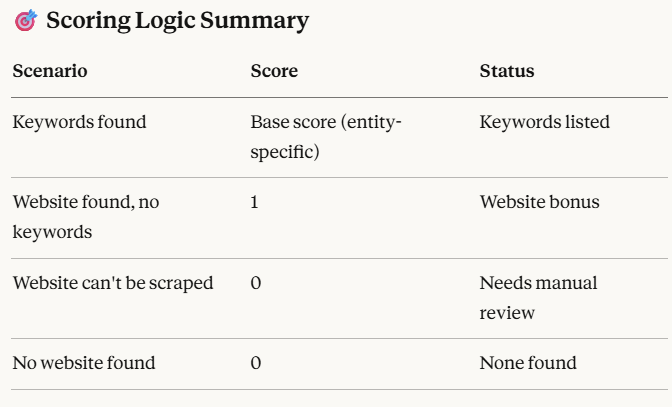

In [ ]:
# Get Website functions :

def get_website_affiliations(entity_name):
  keywords_affiliations="certifications , affiliations, ISO , GDPR , GRI etc."
  """Search for the publisher website using Google Search."""
  return get_website_google(entity_name,extra_keywords=keywords_affiliations)

def get_website_awards(entity_name):
    """Search for the publisher website using Google Search with awards focus."""
    keywords_awards="awards recognition prizes achievements"
    return get_website_google(entity_name,extra_keywords=keywords_awards)

def get_website_data_security(entity_name):
    """Search for the publisher website using Google Search with data security focus."""
    keywords_data_sec = " data security ISO 27001 SOC GDPR CCPA HIPAA privacy"
    return get_website_google(entity_name,extra_keywords=keywords_data_sec)

def get_website_sustainability(entity_name):
    """Search for the publisher website using Google Search with sustainability focus."""
    keywords_sustainability = " sustainability, GRI, ISO 14001, B Corp, Leads, CSR"
    return get_website_google(entity_name,extra_keywords=keywords_sustainability)

def get_website_scientific_validity(entity_name):
    """Search for the publisher website using Google Search with scientific validity focus."""
    keywords_scientifics_val = "ISO 17025 peer-reviewed accredited laboratory scientific methodology"
    return get_website_google(entity_name,extra_keywords=keywords_scientifics_val)

def get_website_content_intgrity(entity_name):
    """Search for the publisher website using Google Search with content integrity focus."""
    keywords_content_integ = "authoriship written by content editors published by"
    return get_website_google(entity_name,extra_keywords=keywords_content_integ)

## Transparency details from Website
def get_website_funding_transparency(entity_name):
    """Search for the publisher website using Google Search with funding transparency focus."""
    keywords_fund_transp = "funding, sponsor, budget, investor, revenue, sources"
    return get_website_google(entity_name,extra_keywords=keywords_fund_transp)

def get_website_governance_transparency(entity_name):
    """Search for the publisher website using Google Search with funding transparency focus."""
    keywords_gov_transp = "board of directors, governance, leadership team"
    return get_website_google(entity_name,extra_keywords=keywords_gov_transp)

def get_website_public_reports_transparency(entity_name):
    """Search for the publisher website using Google Search with funding transparency focus."""
    keywords_pub_report_transp = "annual report, audit report, compliance report, impact report, ESG report, sustainability report"
    return get_website_google(entity_name,extra_keywords=keywords_pub_report_transp)




# Get and parse HTML content from URL
def get_soup(url):
    try:
        headers = {'User-Agent': UserAgent().random}
        response = requests.get(url, headers=headers, timeout=10)
        if response.status_code == 200:
            return BeautifulSoup(response.text, 'html.parser')
    except Exception as e:
        print(f"Error fetching {url}: {e}")
    return None

# Check text functions
def check_affiliations(text):
    found = [cert for cert in Affiliations if cert.lower() in text.lower()]
    return found

def check_awards(text):
    found = [award for award in awards_recog if award.lower() in text.lower()]
    return found

def check_data_security(text):
    found = [cert for cert in data_security_keys if cert.lower() in text.lower()]
    return found

def check_sustainability(text):
    found = [cert for cert in sustainability_keys if cert.lower() in text.lower()]
    return found

def check_scientific_validity(text):
    found = [cert for cert in scientific_validity_keys if cert.lower() in text.lower()]
    return found

def check_content_integrity(text):
    found = [cert for cert in content_intergrity_keys if cert.lower() in text.lower()]
    return found

## Transparency details from Website
def check_fund_transp(text):
    found = [cert for cert in funding_transparency_keys if cert.lower() in text.lower()]
    return found

def check_gov_trasnp(text):
    found = [cert for cert in governance_transparency_keys if cert.lower() in text.lower()]
    return found

def check_pub_report_transp(text):
    found = [cert for cert in public_reports_transparency_keys if cert.lower() in text.lower()]
    return found


# Analysis functions
def analyze_entity_affiliation(entity_name, entity_type):
    """Analyze entity affiliations and return results in a DataFrame"""

    print(f"\n🔍 Searching for affiliations: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'affiliations',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_affiliations(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] = 'No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    affil_found = check_affiliations(page_text)

    entity_type_lower = entity_type.lower()
    base_score = ENTITY_affiliation_SCORES.get(entity_type_lower, 0)

    if affil_found:
        final_score = base_score
        affiliations_str = ', '.join(affil_found)
        keywords_count = len(affil_found)
        print(f"✅ Affiliations found: {affiliations_str}")
    else:
      if not website:
        final_score = 0 # No Website found
      else:
        final_score=1 # Website foudn but no keywords
        affiliations_str = 'None found'
        keywords_count = 0
        print("✅ Affiliations found: None found")


    print(f"📊 Affiliation Score: {final_score}")
    print(f"📈 Total Affiliations found: {keywords_count}")

    result_data['keywords_found'] = affiliations_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

    df = pd.DataFrame([result_data])
    return df

def analyze_entity_awards(entity_name, entity_type):
    """Analyze entity awards and recognition and return results in a DataFrame"""

    print(f"\n🏆 Searching for awards: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'awards',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_awards(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] = 'No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    awards_found = check_awards(page_text)

    entity_type_lower = entity_type.lower()
    base_score = Awards_recog_SCORES.get(entity_type_lower, 0)

    if awards_found:
        final_score = base_score
        awards_str = ', '.join(awards_found)
        keywords_count = len(awards_found)
        print(f"✅ Awards found: {awards_str}")
    else:
        if not website:
            final_score = 0  # No website found
        else:
            final_score = 1  # Website found but no keywords
            awards_str = 'None found'
            keywords_count = 0
            print("✅ Awards found: None found")

    print(f"📊 Awards Score: {final_score}")
    print(f"📈 Total Awards found: {keywords_count}")

    result_data['keywords_found'] = awards_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

    df = pd.DataFrame([result_data])
    return df

def analyze_entity_data_security(entity_name, entity_type):
    """Analyze entity data security certifications and return results in a DataFrame"""

    print(f"\n🔒 Searching for data security: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'data_security',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_data_security(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] ='No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    security_found = check_data_security(page_text)

    entity_type_lower = entity_type.lower()
    base_score = data_security_SCORES.get(entity_type_lower, 0)

    if security_found:
        final_score = base_score
        security_str = ', '.join(security_found)
        keywords_count = len(security_found)
        print(f"✅ Data Security found: {security_str}")
    else:
        if not website:
            final_score = 0  # No website found
        else:
            final_score = 1  # Website found but no keywords
            security_str = 'None found'
            keywords_count = 0
            print("✅ Data Security found: None found")

    print(f"📊 Data Security Score: {final_score}")
    print(f"📈 Total Data Security found: {keywords_count}")

    result_data['keywords_found'] = security_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

    df = pd.DataFrame([result_data])
    return df

def analyze_entity_sustainability(entity_name, entity_type):
    """Analyze entity sustainability certifications and return results in a DataFrame"""

    print(f"\n🌱 Searching for sustainability: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'sustainability',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_sustainability(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] ='No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    sustainability_found = check_sustainability(page_text)

    entity_type_lower = entity_type.lower()
    base_score = sustainability_SCORES.get(entity_type_lower, 0)

    if sustainability_found:
        final_score = base_score
        sustainability_str = ', '.join(sustainability_found)
        keywords_count = len(sustainability_found)
        print(f"✅ Sustainability found: {sustainability_str}")
    else:
        if not website:
            final_score = 0  # No website found
        else:
            final_score = 1  # Website found but no keywords
            sustainability_str = 'None found'
            keywords_count = 0
            print("✅ Sustainability found: None found")

    print(f"📊 Sustainability Score: {final_score}")
    print(f"📈 Total Sustainability found: {keywords_count}")

    result_data['keywords_found'] = sustainability_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'


    df = pd.DataFrame([result_data])
    return df

def analyze_entity_scientific_validity(entity_name, entity_type):
    """Analyze entity scientific validity certifications and return results in a DataFrame"""

    print(f"\n🔬 Searching for scientific validity: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'scientific_validity',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_scientific_validity(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] = 'No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    scientific_found = check_scientific_validity(page_text)

    entity_type_lower = entity_type.lower()
    base_score = scientific_validity_SCORES.get(entity_type_lower, 0)

    if scientific_found:
        final_score = base_score
        scientific_str = ', '.join(scientific_found)
        keywords_count = len(scientific_found)
        print(f"✅ Scientific Validity found: {scientific_str}")
    else:
        if not website:
            final_score = 0  # No website found
        else:
            final_score = 1  # Website found but no keywords
            scientific_str = 'None found'
            keywords_count = 0
            print("✅ Scientific Validity found: None found")

    print(f"📊 Scientific Validity Score: {final_score}")
    print(f"📈 Total Scientific Validity found: {keywords_count}")

    result_data['keywords_found'] = scientific_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

    df = pd.DataFrame([result_data])
    return df



def analyze_content_intigrity(entity_name, entity_type):
    """Analyze entity content integrity and return results in a DataFrame"""

    print(f"\n🔬 Searching for scientific validity: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'content_intigrity',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_content_intgrity(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] = 'No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    content_integrity_found = check_content_integrity(page_text)

    entity_type_lower = entity_type.lower()
    base_score = content_integrity_SCORES.get(entity_type_lower, 0)

    if content_integrity_found:
        final_score = base_score
        content_int_str = ', '.join(content_integrity_found)
        keywords_count = len(content_integrity_found)
        print(f"✅ Content Integrity found: {content_int_str}")
    else:
        if not website:
            final_score = 0  # No website found
        else:
            final_score = 1  # Website found but no keywords
            content_int_str = 'None found'
            keywords_count = 0
            print("✅ Content Integrity Reports found: None found")

    print(f"📊 Content Integrity Score: {final_score}")
    print(f"📈 Total Content Integrity found: {keywords_count}")

    result_data['keywords_found'] = content_int_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

    df = pd.DataFrame([result_data])
    return df



def analyze_funding_transparency_web(entity_name, entity_type):
    """Analyze entity funding transparency and return results in a DataFrame"""

    print(f"\n🔬 Searching for funding transparency from website: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'Funding Transparency',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_funding_transparency(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        result_data['keywords_count'] = 0
        result_data['website_found'] = 'No'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    soup = get_soup(website)
    if not soup:
        print("❌ Could not fetch or parse the website.")
        result_data['keywords_found'] = 'Website error'
        result_data['keywords_count'] = 0
        result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
        result_data['website_found'] ='Yes'
        result_data['website'] = website
        result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
        return pd.DataFrame([result_data])

    page_text = soup.get_text(separator=' ', strip=True)
    funding_transparency_found = check_fund_transp(page_text)

    entity_type_lower = entity_type.lower()
    base_score = funding_transparency_SCORES.get(entity_type_lower, 0)

    if funding_transparency_found:
        final_score = base_score
        funding_transp_str = ', '.join(funding_transparency_found)
        keywords_count = len(funding_transparency_found)
        print(f"✅ Content Integrity found: {funding_transp_str}")
    else:
        if not website:
            final_score = 0  # No website found
        else:
            final_score = 1  # Website found but no keywords
            funding_transp_str = 'None found'
            keywords_count = 0
            print("✅ Public Reports Transparency found: None found")

    print(f"📊 Funding Transparency Score: {final_score}")
    print(f"📈 Total Funding Transparency found: {keywords_count}")

    result_data['keywords_found'] = funding_transp_str
    result_data['website_found'] = 'Yes' if website else 'No'
    result_data['website'] = website
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score
    result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

    df = pd.DataFrame([result_data])
    return df



def analyze_governance_transparency_web(entity_name, entity_type):
        """Analyze entity governance transparency and return results in a DataFrame"""

        print(f"\n🏛️ Searching for governance transparency from website: {entity_name}")

        result_data = {
            'entity_name': entity_name,
            'entity_type': entity_type.lower(),
            'checked_for': 'Governance Transparency',
            'keywords_found': [],
            'keywords_count': 0,
            'score': 0
        }

        website = get_website_governance_transparency(entity_name)
        if not website:
            print("❌ No official website found.")
            result_data['keywords_found'] = 'None found'
            result_data['keywords_count'] = 0
            result_data['website_found'] = 'No'
            return pd.DataFrame([result_data])

        print(f"🌐 Website found: {website}")

        soup = get_soup(website)
        if not soup:
            print("❌ Could not fetch or parse the website.")
            result_data['keywords_found'] = 'Website error'
            result_data['keywords_count'] = 0
            result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
            result_data['website_found'] ='Yes'
            result_data['website'] = website
            result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
            return pd.DataFrame([result_data])

        page_text = soup.get_text(separator=' ', strip=True)
        governance_transparency_found = check_gov_trasnp(page_text)

        entity_type_lower = entity_type.lower()
        base_score = governance_transparency_SCORES.get(entity_type_lower, 0)

        if governance_transparency_found:
            final_score = base_score
            governance_transp_str = ', '.join(governance_transparency_found)
            keywords_count = len(governance_transparency_found)
            print(f"✅ Governance Transparency found: {governance_transp_str}")
        else:
            if not website:
                final_score = 0  # No website found
            else:
                final_score = 1  # Website found but no keywords
                governance_transp_str = 'None found'
                keywords_count = 0
                print("✅ Public Reports Transparency found: None found")

        print(f"📊 Governance Transparency Score: {final_score}")
        print(f"📈 Total Governance Transparency found: {keywords_count}")

        result_data['keywords_found'] = governance_transp_str
        result_data['website_found'] = 'Yes' if website else 'No'
        result_data['website'] = website
        result_data['keywords_count'] = keywords_count
        result_data['score'] = final_score
        result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

        df = pd.DataFrame([result_data])
        return df



def analyze_public_reports_transparency_web(entity_name, entity_type):
        """Analyze entity public reports transparency and return results in a DataFrame"""

        print(f"\n📋 Searching for public reports transparency from website: {entity_name}")

        result_data = {
            'entity_name': entity_name,
            'entity_type': entity_type.lower(),
            'checked_for': 'Public Reports Transparency',
            'keywords_found': [],
            'keywords_count': 0,
            'score': 0
        }

        website = get_website_public_reports_transparency(entity_name)
        if not website:
            print("❌ No official website found.")
            result_data['keywords_found'] = 'None found'
            result_data['keywords_count'] = 0
            result_data['website_found'] = 'No'
            return pd.DataFrame([result_data])

        print(f"🌐 Website found: {website}")

        soup = get_soup(website)
        if not soup:
            print("❌ Could not fetch or parse the website.")
            result_data['keywords_found'] = 'Website error'
            result_data['keywords_count'] = 0
            result_data['score'] = 0  # Assign score of 0 when website exists but can't be fetched
            result_data['website_found'] ='Yes'
            result_data['website'] = website
            result_data['admin_score_reqd?'] = 'Yes ! Could not scrape'
            return pd.DataFrame([result_data])

        page_text = soup.get_text(separator=' ', strip=True)
        public_reports_transparency_found = check_pub_report_transp(page_text)

        entity_type_lower = entity_type.lower()
        base_score = public_reports_transparency_SCORES.get(entity_type_lower, 0)

        if public_reports_transparency_found:
            final_score = base_score
            public_reports_transp_str = ', '.join(public_reports_transparency_found)
            keywords_count = len(public_reports_transparency_found)
            print(f"✅ Public Reports Transparency found: {public_reports_transp_str}")

        else:
            if not website:
                final_score = 0  # No website found
            else:
                final_score = 1  # Website found but no keywords
                public_reports_transp_str = 'None found'
                keywords_count = 0
                print("✅ Public Reports Transparency found: None found")


        print(f"📊 Public Reports Transparency Score: {final_score}")
        print(f"📈 Total Public Reports Transparency found: {keywords_count}")

        result_data['keywords_found'] = public_reports_transp_str
        result_data['website_found'] = 'Yes' if website else 'No'
        result_data['website'] = website
        result_data['keywords_count'] = keywords_count
        result_data['score'] = final_score
        result_data['admin_score_reqd?'] = 'No' if soup else 'Yes ! Could not scrape'

        df = pd.DataFrame([result_data])
        return df

# Sec 5 : Additional analysis for pdfs published in company websites for funding , governance and public reports transparency and final scoring metrics

## Broad description of the PDF Document Analysis codes:
- What it does: Finds and reads PDF reports published by companies
- How it works: Searches Google for PDF reports (like "Company X annual report PDF")

- Handles two scenarios:
  - Direct PDF link → Downloads and reads the PDF immediately
  - Webpage with PDFs → Finds up to 5 PDFs on the page, downloads and reads each one

- Extracts text from PDFs (first 10 pages only, using 2 different methods)
Searches for keywords in the extracted text (same as web analysis) and gives points as below:
  - Found keywords in PDF = Full points
  - Found PDF but no keywords = 1 point (bonus for publishing reports)
  - No PDF = 0 points


- Categories checked (3 total): Funding transparency, Governance transparency, Public reports

- Smart feature: Automatically detects if the search result is a PDF file or a regular webpage, then processes accordingly




### 📄 PDF Text Extraction Function
extract_text_from_pdf_url(pdf_url)
Purpose: Download and extract text from PDF documents
Two-Tier Extraction Strategy:

- Method 1: pdfplumber (better for complex layouts, tables)
- Method 2: PyPDF2 (fallback if pdfplumber fails)

- Process:
  - Downloads PDF with 30-second timeout
  - Extracts text from first 10 pages only (performance optimization)
  - Returns extracted text or empty string if both methods fail


### 🔗 PDF Link Discovery Function
find_pdf_links(soup, base_url)
- Purpose: Find all PDF links on a webpage
- Detection Methods:
    - Links ending with .pdf
    - Links containing "pdf" in URL
    - Links with keywords: "annual report", "transparency report", "financial report", "governance", "funding"
    - Returns: Up to 5 PDF URLs (prevents overload)

### 🔍 PDF-Specific Search Functions
- Purpose: Search for pages containing PDF reports

- get_website_funding_transparency_pdf() - Keywords: "funding report, sponsor report, budget report, investor, revenue sources, donor"
- get_website_governance_transparency_pdf() - Keywords: "board of directors, governance, leadership team, organizational pdf report"
- get_website_public_reports_transparency_pdf() - Keywords: "annual report, audit report, compliance report, impact report, ESG report, sustainability report"

Each function: Uses Google search with PDF-focused keywords → Returns URL

### 🔎 PDF Keyword Checking Functions
- Purpose: Search for transparency keywords in PDF text

- check_funding_transparency() - Finds funding-related keywords
- check_governance_transparency() - Finds governance-related keywords
- check_public_reports_transparency() - Finds public report keywords

Each function: Takes text → Returns list of found keywords (case-insensitive)

### 📊 PDF Transparency Analysis Functions (3 Total)
- Purpose: Analyze transparency by processing PDF documents
Standard Process (All 3 Functions Follow This):

Initialize - Set up result dictionary
Search - Find PDF reports or pages containing PDFs
Check Website - If not found → Score = 0, return early
URL Type Check - Determine if URL is direct PDF or webpage

- Branch A - Direct PDF:

    - Extract text from PDF directly
    - Search for keywords in PDF
    - Mark pdf_found = True


- Branch B - Webpage:

    - Parse HTML with BeautifulSoup
    - Extract webpage text
    - Find PDF links on page (up to 5)
    - Download and extract text from each PDF
    - Search for keywords in both webpage and PDFs
    - Mark pdf_found = True if PDFs exist


- Combine Results - Merge keywords from all sources, remove duplicates
Calculate Score:

- Keywords found → Score = Base score (entity-specific)
- PDF found, no keywords → Score = 1 (PDF bonus)
- No PDF found → Score = 0


- Return DataFrame - Single-row DataFrame with results

### Individual Functions:

- analyze_entity_funding_transparency_pdf() - 💰 Analyzes funding reports in PDFs
- analyze_entity_governance_transparency_pdf() - 🏛️ Analyzes governance reports in PDFs
- analyze_entity_public_reports_transparency_pdf() - 📋 Analyzes annual/public reports in PDFs


### 🎯 Master Orchestration Function
- analyze_entity_complete_with_transparency(entity_name, entity_type)
- Purpose: Run complete 12-category trustworthiness analysis
Executes in Order:

- 6 Core Metrics: Affiliations, Awards, Data Security, Sustainability, Scientific Validity, Content Integrity
- 3 Web Transparency: Funding (Web), Governance (Web), Public Reports (Web)
- 3 PDF Transparency: Funding (PDF), Governance (PDF), Public Reports (PDF)

- Returns: Combined DataFrame with 12 rows (one per category)

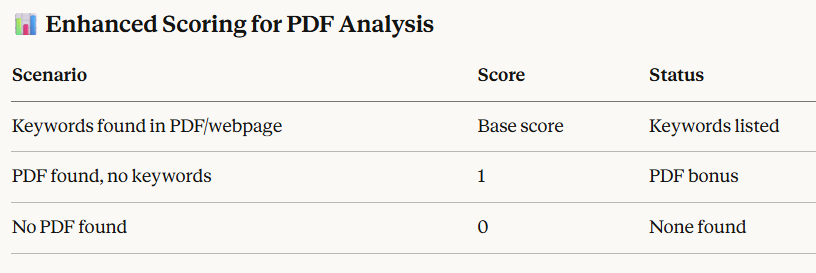

In [ ]:
# Enhanced Website search functions with PDF processing for transparency metrics


# PDF processing function
def extract_text_from_pdf_url(pdf_url):
    """Extract text from PDF URL using multiple methods"""
    try:
        headers = {'User-Agent': UserAgent().random}
        response = requests.get(pdf_url, headers=headers, timeout=30)

        if response.status_code == 200:
            pdf_content = io.BytesIO(response.content)

            # Method 1: Try pdfplumber first (better for complex layouts)
            try:
                with pdfplumber.open(pdf_content) as pdf:
                    text = ""
                    for page in pdf.pages[:10]:  # Limit to first 10 pages for performance
                        page_text = page.extract_text()
                        if page_text:
                            text += page_text + "\n"
                    if text.strip():
                        return text
            except Exception as e:
                print(f"pdfplumber failed: {e}")

            # Method 2: Fallback to PyPDF2
            try:
                pdf_content.seek(0)  # Reset stream position
                reader = PyPDF2.PdfReader(pdf_content)
                text = ""
                for page_num in range(min(len(reader.pages), 10)):  # Limit to first 10 pages
                    page = reader.pages[page_num]
                    page_text = page.extract_text()
                    if page_text:
                        text += page_text + "\n"
                return text
            except Exception as e:
                print(f"PyPDF2 failed: {e}")

    except Exception as e:
        print(f"Error downloading PDF from {pdf_url}: {e}")

    return ""

def find_pdf_links(soup, base_url):
    """Find all PDF links on a webpage"""
    pdf_links = []

    # Look for direct PDF links
    for link in soup.find_all('a', href=True):
        href = link['href']
        full_url = urljoin(base_url, href)

        # Check if it's a PDF link
        if (href.lower().endswith('.pdf') or
            'pdf' in href.lower() or
            any(keyword in link.get_text().lower() for keyword in
                ['annual report', 'transparency report', 'financial report', 'governance', 'funding'])):
            pdf_links.append(full_url)

    return pdf_links[:5]  # Limit to first 5 PDFs to avoid overloading

def get_website_funding_transparency_pdf(entity_name):
  """Search for the publisher website using Google Search with funding transparency focus."""
  keywords_fund_transp = "funding report, sponsor report, budget report, investor, revenue sources, donor, pdf report"
  return get_website_google(entity_name,extra_keywords=keywords_fund_transp)

def get_website_governance_transparency_pdf(entity_name):
    """Search for the publisher website using Google Search with funding transparency focus."""
    keywords_gov_transp = "board of directors, governance , leadership team,organizational pdf report"
    return get_website_google(entity_name,extra_keywords=keywords_gov_transp)

def get_website_public_reports_transparency_pdf(entity_name):
    """Search for the publisher website using Google Search with funding transparency focus."""
    keywords_pub_report_transp = "annual report, audit report, compliance report, impact report, ESG report , sustainability report"
    return get_website_google(entity_name,extra_keywords=keywords_pub_report_transp)


# Text analysis functions for transparency metrics
def check_funding_transparency(text):
    found = [keyword for keyword in funding_transparency_keys if keyword.lower() in text.lower()]
    return found

def check_governance_transparency(text):
    found = [keyword for keyword in governance_transparency_keys if keyword.lower() in text.lower()]
    return found

def check_public_reports_transparency(text):
    found = [keyword for keyword in public_reports_transparency_keys if keyword.lower() in text.lower()]
    return found

# Enhanced analysis functions with PDF processing
def analyze_entity_funding_transparency_pdf(entity_name, entity_type):
    """Analyze entity funding transparency including PDF content"""

    print(f"\n💰 Searching for funding transparency:in pdf report {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'funding_transparency_pdf',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_funding_transparency_pdf(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    # Track if we found a PDF
    pdf_found = False


    # **NEW: Check if the website itself is a PDF**
    if website.lower().endswith('.pdf'):
        print("📄 URL is a PDF file, analyzing directly...")
        pdf_found = True  # Mark that we found a PDF
        pdf_text = extract_text_from_pdf_url(website)

        if pdf_text:
            funding_found = check_funding_transparency(pdf_text)
        else:
            funding_found = []
            print("❌ Could not extract text from PDF.")

        all_keywords = list(set(funding_found))
    else:
        # **EXISTING: Website is a regular webpage**
        soup = get_soup(website)
        if not soup:
            print("❌ Could not fetch or parse the website.")
            result_data['keywords_found'] = 'Website error'
            return pd.DataFrame([result_data])

        # Analyze main page text
        page_text = soup.get_text(separator=' ', strip=True)
        funding_found = check_funding_transparency(page_text)

        # Look for and analyze PDFs
        pdf_links = find_pdf_links(soup, website)
        print(f"📄 Found {len(pdf_links)} PDF links")

        pdf_keywords = []
        for pdf_url in pdf_links:
            print(f"📖 Processing PDF: {pdf_url}")
            pdf_text = extract_text_from_pdf_url(pdf_url)
            if pdf_text:
                pdf_keywords.extend(check_funding_transparency(pdf_text))

        # Combine findings
        all_keywords = list(set(funding_found + pdf_keywords))

    # **REST OF THE FUNCTION REMAINS THE SAME**
    entity_type_lower = entity_type.lower()
    base_score = funding_transparency_SCORES.get(entity_type_lower, 0)

    if all_keywords:
        final_score = base_score
        keywords_str = ', '.join(all_keywords)
        keywords_count = len(all_keywords)
        print(f"✅ Funding Transparency report found: {keywords_str}")

    elif pdf_found:
        # PDF found but no keywords - assign score of 1
        final_score = 1
        keywords_str = 'PDF found, no keywords'
        keywords_count = 0
        print("✅ PDF found but no governance keywords detected")
    else:
        final_score = 0
        keywords_str = 'None found'
        keywords_count = 0
        print("✅ Funding Transparency report found: None found")

    print(f"📊 Funding Transparency Score from report : {final_score}")
    print(f"📈 Total Keywords found in report: {keywords_count}")

    result_data['keywords_found'] = keywords_str
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score

    return pd.DataFrame([result_data])

def analyze_entity_governance_transparency_pdf(entity_name, entity_type):
    """Analyze entity governance transparency including PDF content"""

    print(f"\n🏛️ Searching for governance transparency: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'governance_transparency_pdf',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_governance_transparency_pdf(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")

    # Track if we found a PDF
    pdf_found = False

    # **NEW: Check if the website itself is a PDF**
    if website.lower().endswith('.pdf'):
        print("📄 URL is a PDF file, analyzing directly...")
        pdf_found = True  # Mark that we found a PDF
        pdf_text = extract_text_from_pdf_url(website)


        if pdf_text:
            governance_found = check_governance_transparency(pdf_text)
        else:
            governance_found = []
            print("❌ Could not extract text from PDF.")

        all_keywords = list(set(governance_found))
    else:
        # **EXISTING: Website is a regular webpage**
        soup = get_soup(website)
        if not soup:
            print("❌ Could not fetch or parse the website.")
            result_data['keywords_found'] = 'Website error'
            return pd.DataFrame([result_data])

        # Analyze main page text
        page_text = soup.get_text(separator=' ', strip=True)
        governance_found = check_governance_transparency(page_text)

        # Look for and analyze PDFs
        pdf_links = find_pdf_links(soup, website)
        print(f"📄 Found {len(pdf_links)} PDF links")

        pdf_keywords = []
        for pdf_url in pdf_links:
            print(f"📖 Processing PDF: {pdf_url}")
            pdf_text = extract_text_from_pdf_url(pdf_url)
            if pdf_text:
                pdf_keywords.extend(check_governance_transparency(pdf_text))

        # Combine findings
        all_keywords = list(set(governance_found + pdf_keywords))

    # **REST OF THE FUNCTION REMAINS THE SAME**
    entity_type_lower = entity_type.lower()
    base_score = governance_transparency_SCORES.get(entity_type_lower, 0)

    if all_keywords:
        final_score = base_score
        keywords_str = ', '.join(all_keywords)
        keywords_count = len(all_keywords)
        print(f"✅ Governance Transparency report found: {keywords_str}")
    elif pdf_found:
        # PDF found but no keywords - assign score of 1
        final_score = 1
        keywords_str = 'PDF found, no keywords'
        keywords_count = 0
        print("✅ PDF found but no governance keywords detected")
    else:
        # No PDF found
        final_score = 0
        keywords_str = 'None found'
        keywords_count = 0
        print("✅ Governance Transparency report found: None found")

    print(f"📊 Governance Transparency Score from report: {final_score}")
    print(f"📈 Total Keywords found: {keywords_count}")

    result_data['keywords_found'] = keywords_str
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score

    return pd.DataFrame([result_data])

def analyze_entity_public_reports_transparency_pdf(entity_name, entity_type):
    """Analyze entity public reports transparency including PDF content"""

    print(f"\n📋 Searching for public reports transparency: {entity_name}")

    result_data = {
        'entity_name': entity_name,
        'entity_type': entity_type.lower(),
        'checked_for': 'public_reports_transparency_pdf',
        'keywords_found': [],
        'keywords_count': 0,
        'score': 0
    }

    website = get_website_public_reports_transparency_pdf(entity_name)
    if not website:
        print("❌ No official website found.")
        result_data['keywords_found'] = 'None found'
        return pd.DataFrame([result_data])

    print(f"🌐 Website found: {website}")
    # Track if we found a PDF
    pdf_found = False

    # **NEW: Check if the website itself is a PDF**
    if website.lower().endswith('.pdf'):
        print("📄 URL is a PDF file, analyzing directly...")
        pdf_found = True  # Mark that we found a PDF
        pdf_text = extract_text_from_pdf_url(website)

        if pdf_text:
            reports_found = check_public_reports_transparency(pdf_text)
        else:
            reports_found = []
            print("❌ Could not extract text from PDF.")

        all_keywords = list(set(reports_found))
    else:
        # **EXISTING: Website is a regular webpage**
        soup = get_soup(website)
        if not soup:
            print("❌ Could not fetch or parse the website.")
            result_data['keywords_found'] = 'Website error'
            return pd.DataFrame([result_data])

        # Analyze main page text
        page_text = soup.get_text(separator=' ', strip=True)
        reports_found = check_public_reports_transparency(page_text)

        # Look for and analyze PDFs
        pdf_links = find_pdf_links(soup, website)
        print(f"📄 Found {len(pdf_links)} PDF links")

        pdf_keywords = []
        for pdf_url in pdf_links:
            print(f"📖 Processing PDF: {pdf_url}")
            pdf_text = extract_text_from_pdf_url(pdf_url)
            if pdf_text:
                pdf_keywords.extend(check_public_reports_transparency(pdf_text))

        # Combine findings
        all_keywords = list(set(reports_found + pdf_keywords))

    # **REST OF THE FUNCTION REMAINS THE SAME**
    entity_type_lower = entity_type.lower()
    base_score = public_reports_transparency_SCORES.get(entity_type_lower, 0)

    if all_keywords:
        final_score = base_score
        keywords_str = ', '.join(all_keywords)
        keywords_count = len(all_keywords)
        print(f"✅ Public Reports Transparency found: {keywords_str}")
    elif pdf_found:
        # PDF found but no keywords - assign score of 1
        final_score = 1
        keywords_str = 'PDF found, no keywords'
        keywords_count = 0
        print("✅ PDF found but no governance keywords detected")
    else:
        final_score = 0
        keywords_str = 'None found'
        keywords_count = 0
        print("✅ Public Reports Transparency found: None found")

    print(f"📊 Public Reports Transparency Score: {final_score}")
    print(f"📈 Total Keywords found: {keywords_count}")

    result_data['keywords_found'] = keywords_str
    result_data['keywords_count'] = keywords_count
    result_data['score'] = final_score

    return pd.DataFrame([result_data])

# Updated complete analysis function
def analyze_entity_complete_with_transparency(entity_name, entity_type):
    """
    Analyze entity for all categories including transparency metrics

    Args:
        entity_name (str): Name of the entity to analyze
        entity_type (str): Type of entity (startup, media, ngo, etc.)

    Returns:
        pandas.DataFrame: Combined results for all analysis types
    """

    # Get results for all analysis types (existing + new)
    affiliations_df = analyze_entity_affiliation(entity_name, entity_type)
    awards_df = analyze_entity_awards(entity_name, entity_type)
    data_security_df = analyze_entity_data_security(entity_name, entity_type)
    sustainability_df = analyze_entity_sustainability(entity_name, entity_type)
    scientific_validity_df = analyze_entity_scientific_validity(entity_name, entity_type)
    content_integrity_df=analyze_content_intigrity(entity_name, entity_type)


    # New transparency metrics from web
    funding_transparency_df_web = analyze_funding_transparency_web(entity_name, entity_type)
    governance_transparency_df_web = analyze_governance_transparency_web(entity_name, entity_type)
    public_reports_transparency_df_web = analyze_public_reports_transparency_web(entity_name, entity_type)

    # New transparency metrics from pdf
    funding_transparency_df_pdf = analyze_entity_funding_transparency_pdf(entity_name, entity_type)
    governance_transparency_df_pdf = analyze_entity_governance_transparency_pdf(entity_name, entity_type)
    public_reports_transparency_df_pdf = analyze_entity_public_reports_transparency_pdf(entity_name, entity_type)

    # Combine all DataFrames
    combined_df = pd.concat([
        affiliations_df,
        awards_df,
        data_security_df,
        sustainability_df,
        scientific_validity_df,
        content_integrity_df,
        funding_transparency_df_web,
        governance_transparency_df_web,
        public_reports_transparency_df_web,
        funding_transparency_df_pdf,
        governance_transparency_df_pdf,
        public_reports_transparency_df_pdf
    ], ignore_index=True)

    return combined_df



In [ ]:
# Example 1:
greenomy_strtup_df=analyze_entity_complete_with_transparency("Greenomy", "Startup")
greenomy_strtup_df


🔍 Searching for affiliations: Greenomy
🌐 Website found: https://academy.greenomy.io/course/the-eu-taxonomy-and-sustainable-finance-reporting
✅ Affiliations found: PRI
📊 Affiliation Score: 3
📈 Total Affiliations found: 1

🏆 Searching for awards: Greenomy
🌐 Website found: https://grammy.com/awards/lifetime-achievement-awards
✅ Awards found: None found
📊 Awards Score: 1
📈 Total Awards found: 0

🔒 Searching for data security: Greenomy
🌐 Website found: https://www.positiongreen.com/wp-content/uploads/2025/11/Greenomy-Privacy-Policy.pdf
✅ Data Security found: None found
📊 Data Security Score: 1
📈 Total Data Security found: 0

🌱 Searching for sustainability: Greenomy
🌐 Website found: https://fintech.global/2025/01/27/how-greenomys-b-corp-status-advances-esg-reporting-and-corporate-responsibility/
❌ Could not fetch or parse the website.

🔬 Searching for scientific validity: Greenomy
❌ No official website found.

🔬 Searching for scientific validity: Greenomy
🌐 Website found: https://www.degruy

,entity_name,entity_type,checked_for,keywords_found,keywords_count,score,website_found,website,admin_score_reqd?
0,Greenomy,startup,affiliations,PRI,1,3,Yes,https://academy.greenomy.io/course/the-eu-taxo...,No
1,Greenomy,startup,awards,None found,0,1,Yes,https://grammy.com/awards/lifetime-achievement...,No
2,Greenomy,startup,data_security,None found,0,1,Yes,https://www.positiongreen.com/wp-content/uploa...,No
3,Greenomy,startup,sustainability,Website error,0,0,Yes,https://fintech.global/2025/01/27/how-greenomy...,Yes ! Could not scrape
4,Greenomy,startup,scientific_validity,None found,0,0,No,NaN,NaN
5,Greenomy,startup,content_intigrity,published by,1,2,Yes,https://www.degruyterbrill.com/document/doi/10...,No
6,Greenomy,startup,Funding Transparency,Website error,0,0,Yes,https://pitchbook.com/profiles/company/462988-27,Yes ! Could not scrape
7,Greenomy,startup,Governance Transparency,"board of directors, board of directors",2,3,Yes,https://www.positiongreen.com/greenomy/,No
8,Greenomy,startup,Public Reports Transparency,"sustainability report, ESG report, sustainabil...",3,5,Yes,https://www.positiongreen.com/greenomy/,No
9,Greenomy,startup,funding_transparency_pdf,None found,0,0,NaN,NaN,NaN


In [ ]:
# Example 2:
clarity_ai_df=analyze_entity_complete_with_transparency("Clarity AI", "Startup")
clarity_ai_df


🔍 Searching for affiliations: Clarity AI
🌐 Website found: https://trust.clarity.ai/
✅ Affiliations found: None found
📊 Affiliation Score: 1
📈 Total Affiliations found: 0

🏆 Searching for awards: Clarity AI
🌐 Website found: https://clarity.ai/in-the-news/clarity-ai-honored-in-fast-company-magazines-2023-brands-that-matter-list/
✅ Awards found: None found
📊 Awards Score: 1
📈 Total Awards found: 0

🔒 Searching for data security: Clarity AI
🌐 Website found: https://trust.clarity.ai/
✅ Data Security found: None found
📊 Data Security Score: 1
📈 Total Data Security found: 0

🌱 Searching for sustainability: Clarity AI
🌐 Website found: https://clarity.ai/sustainability-report/
✅ Sustainability found: None found
📊 Sustainability Score: 1
📈 Total Sustainability found: 0

🔬 Searching for scientific validity: Clarity AI
🌐 Website found: https://intuitionlabs.ai/pdfs/iso-iec-17025-a-complete-guide-to-lab-accreditation.pdf
✅ Scientific Validity found: None found
📊 Scientific Validity Score: 1
📈 Tota

,entity_name,entity_type,checked_for,keywords_found,keywords_count,score,website_found,website,admin_score_reqd?
0,Clarity AI,startup,affiliations,None found,0,1,Yes,https://trust.clarity.ai/,No
1,Clarity AI,startup,awards,None found,0,1,Yes,https://clarity.ai/in-the-news/clarity-ai-hono...,No
2,Clarity AI,startup,data_security,None found,0,1,Yes,https://trust.clarity.ai/,No
3,Clarity AI,startup,sustainability,None found,0,1,Yes,https://clarity.ai/sustainability-report/,No
4,Clarity AI,startup,scientific_validity,None found,0,1,Yes,https://intuitionlabs.ai/pdfs/iso-iec-17025-a-...,No
5,Clarity AI,startup,content_intigrity,Website error,0,0,Yes,https://www.facebook.com/groups/14041164171420...,Yes ! Could not scrape
6,Clarity AI,startup,Funding Transparency,None found,0,1,Yes,https://www.wamda.com/2025/09/wamda-capital-ba...,No
7,Clarity AI,startup,Governance Transparency,None found,0,1,Yes,https://clarity.ai/our-team/,No
8,Clarity AI,startup,Public Reports Transparency,"sustainability report, ESG report, sustainabil...",3,5,Yes,https://clarity.ai/sustainability-report/,No
9,Clarity AI,startup,funding_transparency_pdf,"PDF found, no keywords",0,1,NaN,NaN,NaN


In [ ]:
# Examplke 3: Climate Bonds Initiative
analyze_entity_complete_with_transparency("Climate Bonds Initiative", "NGO")


🔍 Searching for affiliations: Climate Bonds Initiative
🌐 Website found: https://www.climatebonds.net/expertise/standard-sector-criteria-certification/certification
✅ Affiliations found: PRI, GRI
📊 Affiliation Score: 3
📈 Total Affiliations found: 2

🏆 Searching for awards: Climate Bonds Initiative
🌐 Website found: https://www.climatebonds.net/news-events/blog/driving-change-winners-9th-climate-bonds-awards
❌ Could not fetch or parse the website.

🔒 Searching for data security: Climate Bonds Initiative
🌐 Website found: https://www.climatebonds.net/privacy
❌ Could not fetch or parse the website.

🌱 Searching for sustainability: Climate Bonds Initiative
🌐 Website found: https://www.climatebonds.net/
✅ Sustainability found: GRI
📊 Sustainability Score: 4
📈 Total Sustainability found: 1

🔬 Searching for scientific validity: Climate Bonds Initiative
🌐 Website found: https://www.climatebonds.net/files/documents/Governance-Supporting-Doc_Climate-Bonds-Scientific-Framework.pdf
❌ Could not fetch 

,entity_name,entity_type,checked_for,keywords_found,keywords_count,score,website_found,website,admin_score_reqd?
0,Climate Bonds Initiative,ngo,affiliations,"PRI, GRI",2,3,Yes,https://www.climatebonds.net/expertise/standar...,No
1,Climate Bonds Initiative,ngo,awards,Website error,0,0,Yes,https://www.climatebonds.net/news-events/blog/...,Yes ! Could not scrape
2,Climate Bonds Initiative,ngo,data_security,Website error,0,0,Yes,https://www.climatebonds.net/privacy,Yes ! Could not scrape
3,Climate Bonds Initiative,ngo,sustainability,GRI,1,4,Yes,https://www.climatebonds.net/,No
4,Climate Bonds Initiative,ngo,scientific_validity,Website error,0,0,Yes,https://www.climatebonds.net/files/documents/G...,Yes ! Could not scrape
5,Climate Bonds Initiative,ngo,content_intigrity,None found,0,1,Yes,https://www.climatebonds.net/files/documents/p...,No
6,Climate Bonds Initiative,ngo,Funding Transparency,None found,0,1,Yes,https://www.climatebonds.net/files/documents/p...,No
7,Climate Bonds Initiative,ngo,Governance Transparency,leadership team,1,5,Yes,https://www.climatebonds.net/about/team,No
8,Climate Bonds Initiative,ngo,Public Reports Transparency,None found,0,1,Yes,https://www.climatebonds.net/files/documents/p...,No
9,Climate Bonds Initiative,ngo,funding_transparency_pdf,"PDF found, no keywords",0,1,NaN,NaN,NaN


In [ ]:
# Example 4: Carbon Clean
analyze_entity_complete_with_transparency("Carbon Clean", "Startup")


🔍 Searching for affiliations: Carbon Clean
🌐 Website found: https://www.carbonclean.com/en/press-releases/iso-accreditation
✅ Affiliations found: PRI
📊 Affiliation Score: 3
📈 Total Affiliations found: 1

🏆 Searching for awards: Carbon Clean
🌐 Website found: https://www.carbonclean.com/en/press-releases/terra-carta-seal
✅ Awards found: None found
📊 Awards Score: 1
📈 Total Awards found: 0

🔒 Searching for data security: Carbon Clean
🌐 Website found: https://www.protegrity.com/blog/compliance-cheat-sheet-gdpr-vs-cpra-vs-hipaa-vs-soc/
❌ Could not fetch or parse the website.

🌱 Searching for sustainability: Carbon Clean
🌐 Website found: https://www.carbonclean.com/
✅ Sustainability found: None found
📊 Sustainability Score: 1
📈 Total Sustainability found: 0

🔬 Searching for scientific validity: Carbon Clean
🌐 Website found: https://intuitionlabs.ai/pdfs/iso-iec-17025-a-complete-guide-to-lab-accreditation.pdf
✅ Scientific Validity found: None found
📊 Scientific Validity Score: 1
📈 Total Scie

,entity_name,entity_type,checked_for,keywords_found,keywords_count,score,website_found,website,admin_score_reqd?
0,Carbon Clean,startup,affiliations,PRI,1,3,Yes,https://www.carbonclean.com/en/press-releases/...,No
1,Carbon Clean,startup,awards,None found,0,1,Yes,https://www.carbonclean.com/en/press-releases/...,No
2,Carbon Clean,startup,data_security,Website error,0,0,Yes,https://www.protegrity.com/blog/compliance-che...,Yes ! Could not scrape
3,Carbon Clean,startup,sustainability,None found,0,1,Yes,https://www.carbonclean.com/,No
4,Carbon Clean,startup,scientific_validity,None found,0,1,Yes,https://intuitionlabs.ai/pdfs/iso-iec-17025-a-...,No
5,Carbon Clean,startup,content_intigrity,Website error,0,0,Yes,https://www.sciencedirect.com/journal/cleaner-...,Yes ! Could not scrape
6,Carbon Clean,startup,Funding Transparency,None found,0,1,Yes,https://www.carbonclean.com/en/press-releases/...,No
7,Carbon Clean,startup,Governance Transparency,"board of directors, leadership team, board of ...",3,3,Yes,https://www.carbonclean.com/en/press-releases/...,No
8,Carbon Clean,startup,Public Reports Transparency,audit report,1,5,Yes,https://www.earthood.com/earthscoop/carbon-aud...,No
9,Carbon Clean,startup,funding_transparency_pdf,None found,0,0,NaN,NaN,NaN


In [ ]:
# Example 5: Greenbiz
analyze_entity_complete_with_transparency("Greenbiz", "media")


🔍 Searching for affiliations: Greenbiz
🌐 Website found: https://trellis.net/events/greenbiz/frequently-asked-questions/
✅ Affiliations found: PRI, GRI
📊 Affiliation Score: 5
📈 Total Affiliations found: 2

🏆 Searching for awards: Greenbiz
🌐 Website found: https://www.richnerlive.com/greenbiz-awards/honorees/
✅ Awards found: None found
📊 Awards Score: 1
📈 Total Awards found: 0

🔒 Searching for data security: Greenbiz
🌐 Website found: https://sprinto.com/blog/compliance-standards/
✅ Data Security found: ISO 27001, SOC 2, SOC 2 compliance, GDPR, CCPA, HIPAA
📊 Data Security Score: 3
📈 Total Data Security found: 6

🌱 Searching for sustainability: Greenbiz
🌐 Website found: https://www.greenbusinessbenchmark.com/archive/sustainability-certifications-understanding-all-options
✅ Sustainability found: GRI, ISO 14001, B Corp, LEED certified
📊 Sustainability Score: 2
📈 Total Sustainability found: 4

🔬 Searching for scientific validity: Greenbiz
🌐 Website found: https://intuitionlabs.ai/pdfs/iso-ie

,entity_name,entity_type,checked_for,keywords_found,keywords_count,score,website_found,website,admin_score_reqd?
0,Greenbiz,media,affiliations,"PRI, GRI",2,5,Yes,https://trellis.net/events/greenbiz/frequently...,No
1,Greenbiz,media,awards,None found,0,1,Yes,https://www.richnerlive.com/greenbiz-awards/ho...,No
2,Greenbiz,media,data_security,"ISO 27001, SOC 2, SOC 2 compliance, GDPR, CCPA...",6,3,Yes,https://sprinto.com/blog/compliance-standards/,No
3,Greenbiz,media,sustainability,"GRI, ISO 14001, B Corp, LEED certified",4,2,Yes,https://www.greenbusinessbenchmark.com/archive...,No
4,Greenbiz,media,scientific_validity,None found,0,1,Yes,https://intuitionlabs.ai/pdfs/iso-iec-17025-a-...,No
5,Greenbiz,media,content_intigrity,None found,0,1,Yes,https://trellis.net/editorial-guidelines/,No
6,Greenbiz,media,Funding Transparency,None found,0,1,Yes,https://info.greenbiz.com/rs/211-NJY-165/image...,No
7,Greenbiz,media,Governance Transparency,None found,0,1,Yes,https://trellis.net/article/greenbiz-2025-maki...,No
8,Greenbiz,media,Public Reports Transparency,None found,0,1,Yes,https://info.greenbiz.com/rs/211-NJY-165/image...,No
9,Greenbiz,media,funding_transparency_pdf,"PDF found, no keywords",0,1,NaN,NaN,NaN
